In [1]:
%pip install -q pandas numpy matplotlib pyarrow

import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

warnings.filterwarnings("ignore")
drive.mount("/content/drive")

P = Path("/content/drive/MyDrive/Nasa App Challenges/PyroSync")
AGG, H5 = P / "data" / "aggregated" / "phase3", P / "data" / "harmonization" / "phase5"
OUT, REP = P / "data" / "harmonization" / "phase6", P / "reports" / "phase6"
for d in (OUT, REP):
    d.mkdir(parents=True, exist_ok=True)

panel = pd.read_parquet(AGG / "panel_cell_month_2012_2021.parquet")
modis = pd.read_parquet(AGG / "modis_cell_month.parquet")
cvp = pd.read_parquet(H5 / "cv_predictions_nonempty.parquet")
params = json.load(open(H5 / "final_model_parameters.json"))
for d in (panel, modis, cvp):
    d["month"] = pd.to_datetime(d["month"])

assert params["selected_model"] == "Seasonal ratio"
need = {"cell_id", "ix", "iy", "month", "modis_all_n", "modis_terra_n", "modis_aqua_n"}
assert need <= set(modis.columns), need - set(modis.columns)
print("Panel rows:", f"{len(panel):,}", "| MODIS cell-month rows:", f"{len(modis):,}",
      "|", modis["month"].min().date(), "to", modis["month"].max().date())

Mounted at /content/drive
Panel rows: 538,713 | MODIS cell-month rows: 32,017 | 2000-11-01 to 2021-12-01


In [2]:
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
SEASONS = ["DJF", "MAM", "JJA", "SON"]
REGIONS = ["North California", "Central California", "South California"]
def region_of(lat):
    return np.select([lat < 36, lat < 38], ["South California", "Central California"], "North California")

cells = panel.drop_duplicates("cell_id")[["cell_id", "lat"]].copy()
cells["region"] = region_of(cells["lat"].to_numpy())
FIRST_VIIRS_MONTH = pd.Timestamp("2012-02-01")
first_aqua = modis.loc[modis["modis_aqua_n"] > 0, "month"].min()

hist = modis[modis["month"] < FIRST_VIIRS_MONTH].merge(cells[["cell_id", "region"]], on="cell_id", how="left")
assert hist["region"].notna().all(), "historical cell outside the Phase 3 grid"
hist["season"] = hist["month"].dt.month.map(SEASON)
hist["terra_only"] = hist["month"] <= first_aqua

print("First month with Aqua detections:", first_aqua.date())
print("Historical cell-month rows:", f"{len(hist):,}", "| MODIS detections:", f"{hist['modis_all_n'].sum():,}")
print("Terra-only months:", hist.loc[hist["terra_only"], "month"].nunique())

First month with Aqua detections: 2002-07-01
Historical cell-month rows: 16,535 | MODIS detections: 92,669
Terra-only months: 21


In [3]:
panel["season"] = panel["month"].dt.month.map(SEASON)
g = panel.groupby("season")[["viirs_all_n", "modis_all_n", "modis_terra_n"]].sum().loc[SEASONS]
r_sel = (g["viirs_all_n"] / g["modis_all_n"]).to_dict()
r_terra = (g["viirs_all_n"] / g["modis_terra_n"]).to_dict()
for s in SEASONS:
    assert abs(r_sel[s] - params["seasonal_ratio_all_rows"][s]) < 1e-9, "Phase 5 ratios differ"
print("VIIRS per MODIS (Terra+Aqua):", {k: round(v, 3) for k, v in r_sel.items()})
print("VIIRS per Terra detection:   ", {k: round(v, 3) for k, v in r_terra.items()})
print("Terra share of MODIS, 2012-21:", round(g["modis_terra_n"].sum() / g["modis_all_n"].sum(), 3))

VIIRS per MODIS (Terra+Aqua): {'DJF': 3.315, 'MAM': 3.175, 'JJA': 4.275, 'SON': 4.476}
VIIRS per Terra detection:    {'DJF': 7.714, 'MAM': 5.906, 'JJA': 8.145, 'SON': 8.977}
Terra share of MODIS, 2012-21: 0.51


In [4]:
pm = panel.copy()
pm["region"] = region_of(pm["lat"].to_numpy())
pm["year"] = pm["month"].dt.year
key, labels = pd.factorize(pm["region"] + "|" + pm["month"].dt.strftime("%Y-%m"))
G = len(labels)
V, M, T = (pm[c].to_numpy(float) for c in ["viirs_all_n", "modis_all_n", "modis_terra_n"])
p_sel, p_ter = np.zeros(len(pm)), np.zeros(len(pm))
for y in sorted(pm["year"].unique()):
    tr = (pm["year"] != y).to_numpy(); te = ~tr
    gg = pm[tr].groupby("season")[["viirs_all_n", "modis_all_n", "modis_terra_n"]].sum()
    s = pm.loc[te, "season"]
    p_sel[te] = M[te] * s.map(gg["viirs_all_n"] / gg["modis_all_n"]).to_numpy()
    p_ter[te] = T[te] * s.map(gg["viirs_all_n"] / gg["modis_terra_n"]).to_numpy()

cvdf = pd.DataFrame({"rm": labels,
                     "actual": np.bincount(key, weights=V, minlength=G),
                     "sel": np.bincount(key, weights=p_sel, minlength=G),
                     "terra": np.bincount(key, weights=p_ter, minlength=G)})
cvdf[["region", "month"]] = cvdf["rm"].str.split("|", expand=True)
cvdf["month"] = pd.to_datetime(cvdf["month"])
cvdf["season"] = cvdf["month"].dt.month.map(SEASON)

res = {}
for c in ("sel", "terra"):
    res[c] = (cvdf[c] - cvdf["actual"]).abs().sum() / cvdf["actual"].sum()
    print(f"{c:6s} region-month WAPE {res[c]:.4f} | total bias {(cvdf[c].sum() - cvdf['actual'].sum()) / cvdf['actual'].sum() * 100:+.2f}%")
ref = pd.read_csv(H5 / "cv_results.csv").set_index("model").loc["Seasonal ratio", "rm_WAPE"]
assert abs(res["sel"] - ref) < 1e-9, "does not reproduce Phase 5"

sel    region-month WAPE 0.1285 | total bias -0.81%
terra  region-month WAPE 0.1301 | total bias -0.78%


In [5]:
def band(df, col):
    d = df[df[col] > 0].assign(q=lambda x: x["actual"] / x[col])
    t = d.groupby("season")["q"].quantile([.05, .5, .95]).unstack()
    t.columns = ["q05", "q50", "q95"]
    return t.loc[SEASONS]

st = cvdf.groupby(["month", "season"], as_index=False)[["actual", "sel", "terra"]].sum()
bands = {(lvl, m): band(df, m) for lvl, df in [("region", cvdf), ("state", st)] for m in ("sel", "terra")}
for k, v in bands.items():
    print(k); display(v.round(3))

('region', 'sel')


,q05,q50,q95
season,,,
DJF,0.586,0.896,2.271
MAM,0.742,1.074,1.927
JJA,0.679,0.963,1.382
SON,0.523,0.862,1.291


('region', 'terra')


,q05,q50,q95
season,,,
DJF,0.415,1.012,3.016
MAM,0.701,1.038,2.338
JJA,0.670,0.966,1.435
SON,0.449,0.871,1.402


('state', 'sel')


,q05,q50,q95
season,,,
DJF,0.704,0.920,1.460
MAM,0.782,1.033,1.407
JJA,0.829,0.918,1.175
SON,0.581,0.822,1.177


('state', 'terra')


,q05,q50,q95
season,,,
DJF,0.623,1.007,1.760
MAM,0.783,1.039,1.462
JJA,0.835,0.957,1.191
SON,0.595,0.850,1.193


In [6]:
hist["pred"] = np.where(hist["terra_only"], hist["modis_terra_n"] * hist["season"].map(r_terra),
                        hist["modis_all_n"] * hist["season"].map(r_sel))
months = pd.date_range("2000-11-01", "2012-01-01", freq="MS")
idx = pd.MultiIndex.from_product([months, REGIONS], names=["month", "region"])
pr = hist.groupby(["month", "region"])["pred"].sum().reindex(idx, fill_value=0).reset_index()

def finish(d, lvl):
    d = d.copy(); d["season"] = d["month"].dt.month.map(SEASON)
    d["model"] = np.where(d["month"] <= first_aqua, "terra", "sel")
    for q in ("q05", "q95"):
        d[q] = [bands[(lvl, m)].loc[s, q] for m, s in zip(d["model"], d["season"])]
    d["value"], d["lo"], d["hi"] = d["pred"], d["pred"] * d["q05"], d["pred"] * d["q95"]
    d["source"] = np.where(d["model"] == "terra", "predicted (Terra-only)", "predicted (MODIS to VIIRS)")
    return d[["month", "region", "value", "lo", "hi", "source"]]

obs = (panel.assign(region=region_of(panel["lat"].to_numpy()))
       .groupby(["month", "region"])["viirs_all_n"].sum().rename("value").reset_index())
obs = obs.assign(lo=obs["value"], hi=obs["value"], source="observed VIIRS")

prs = pr.groupby("month", as_index=False)["pred"].sum().assign(region="California")
obs_s = obs.groupby("month", as_index=False)["value"].sum().assign(region="California", source="observed VIIRS")
obs_s = obs_s.assign(lo=obs_s["value"], hi=obs_s["value"])
series_region = pd.concat([finish(pr, "region"), obs], ignore_index=True).sort_values(["month", "region"])
series_state = pd.concat([finish(prs, "state"), obs_s[["month", "region", "value", "lo", "hi", "source"]]],
                         ignore_index=True).sort_values("month")

assert series_state["month"].is_unique and len(series_state) == 254
assert len(series_region) == 254 * 3
print("Months:", len(series_state), "|", series_state["month"].min().date(), "to", series_state["month"].max().date())
print(series_state["source"].value_counts().to_string())
annual = series_state.assign(year=series_state["month"].dt.year).groupby("year")["value"].sum().round(0)
display(annual.to_frame("VIIRS-equivalent detections").T)

Months: 254 | 2000-11-01 to 2021-12-01
source
observed VIIRS                119
predicted (MODIS to VIIRS)    114
predicted (Terra-only)         21


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
VIIRS-equivalent detections,3649.0,24960.0,34967.0,45740.0,23976.0,19647.0,47981.0,52697.0,93763.0,33149.0,...,37294.0,40099.0,35979.0,51557.0,32769.0,72754.0,81388.0,19898.0,230608.0,195567.0


In [7]:
cvp["pred"] = cvp["pred_seasonal_ratio"]
rows = []
for k in (1, 2, 4, 8, 16):
    d = cvp.assign(bx=cvp["ix"] // k, by=cvp["iy"] // k)
    r = {"block_km": k * 10, "block_cells": k * k}
    for lab, keys in (("month", ["bx", "by", "month"]), ("year", ["bx", "by", "year"])):
        a = d.groupby(keys)[["viirs_all_n", "pred"]].sum()
        r[f"WAPE_{lab}"] = (a["pred"] - a["viirs_all_n"]).abs().sum() / a["viirs_all_n"].sum()
    rows.append(r)
aoi = pd.DataFrame(rows)
display(aoi.round(3))

,block_km,block_cells,WAPE_month,WAPE_year
0,10,1,0.339,0.279
1,20,4,0.291,0.229
2,40,16,0.242,0.182
3,80,64,0.205,0.146
4,160,256,0.176,0.120


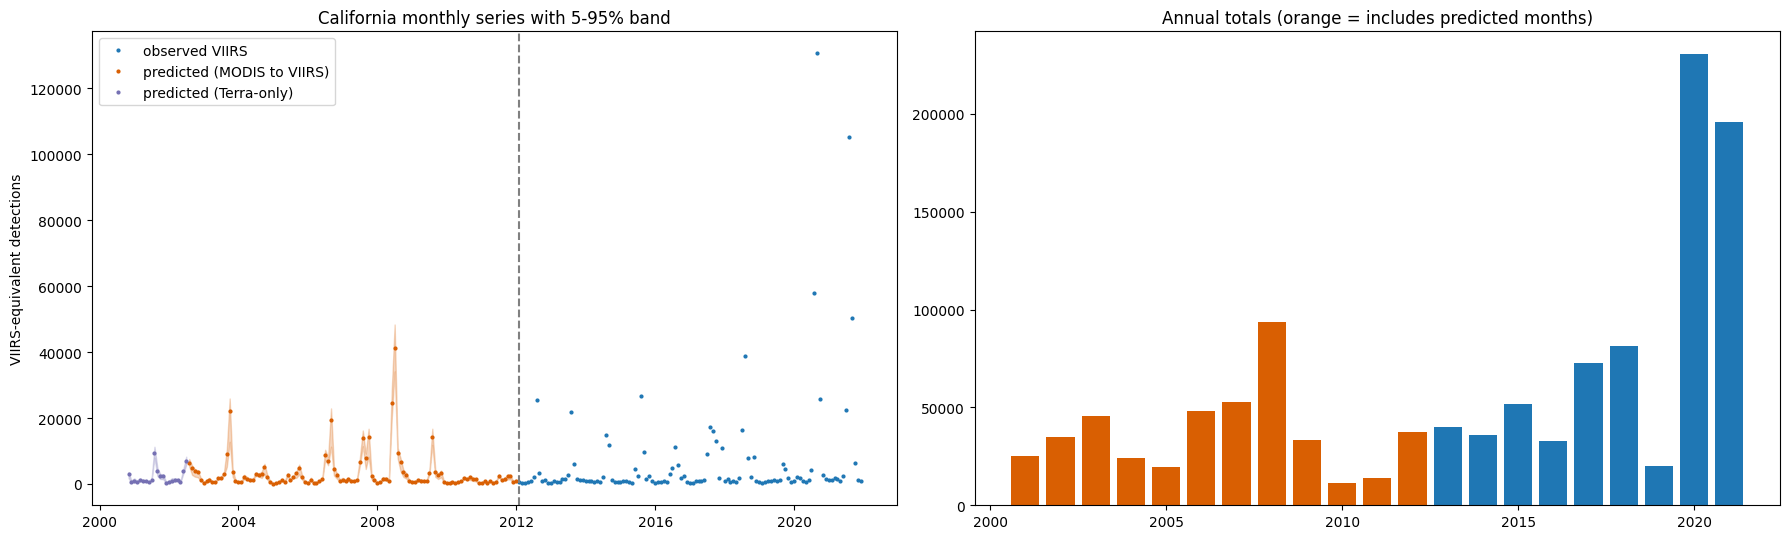

In [8]:
a = series_state.copy(); a["year"] = a["month"].dt.year
fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
for src, c in [("observed VIIRS", "#1f77b4"), ("predicted (MODIS to VIIRS)", "#d95f02"), ("predicted (Terra-only)", "#7570b3")]:
    d = a[a["source"] == src]
    ax[0].plot(d["month"], d["value"], ".", ms=4, color=c, label=src)
    if src != "observed VIIRS":
        ax[0].fill_between(d["month"], d["lo"], d["hi"], color=c, alpha=0.25)
ax[0].axvline(FIRST_VIIRS_MONTH, color="gray", ls="--"); ax[0].legend(); ax[0].set_ylabel("VIIRS-equivalent detections")
ax[0].set_title("California monthly series with 5-95% band")
y = a[(a["year"] >= 2001)].groupby("year").agg(v=("value", "sum"), pred=("source", lambda s: s.ne("observed VIIRS").any()))
ax[1].bar(y.index, y["v"], color=np.where(y["pred"], "#d95f02", "#1f77b4"))
ax[1].set_title("Annual totals (orange = includes predicted months)")
plt.tight_layout(); plt.savefig(REP / "phase6_series.png", dpi=250); plt.show()

In [9]:
series_state.to_csv(OUT / "harmonized_monthly_state.csv", index=False)
series_region.to_csv(OUT / "harmonized_monthly_region.csv", index=False)
pd.concat({f"{l}_{m}": b for (l, m), b in bands.items()}, names=["level_model", "season"]).reset_index() \
  .to_csv(OUT / "prediction_bands.csv", index=False)
aoi.to_csv(OUT / "aoi_error_by_block.csv", index=False)
hist[["cell_id", "ix", "iy", "region", "month", "modis_all_n", "modis_terra_n", "pred", "terra_only"]] \
    .to_parquet(OUT / "predicted_cell_month_pre2012.parquet", index=False)
meta = {"project": "PyroSync", "phase": 6, "model": "Seasonal ratio",
        "ratio_terra_plus_aqua": r_sel, "ratio_terra_only": r_terra,
        "first_aqua_month": str(first_aqua.date()),
        "cv_wape_selected": float(res["sel"]), "cv_wape_terra_only": float(res["terra"]),
        "period_predicted": "2000-11 to 2012-01", "period_observed": "2012-02 to 2021-12"}
with open(OUT / "phase6_metadata.json", "w") as f:
    json.dump(meta, f, indent=4)
print("Saved", len(list(OUT.iterdir())), "files to", OUT)

Saved 6 files to /content/drive/MyDrive/Nasa App Challenges/PyroSync/data/harmonization/phase6


In [10]:
print("=" * 80); print("PYROSYNC — PHASE 6 FINAL REPORT"); print("=" * 80)
print(f"Series: {len(series_state)} months, 2000-11 to 2021-12 "
      f"({(series_state['source'] != 'observed VIIRS').sum()} predicted, {(series_state['source'] == 'observed VIIRS').sum()} observed)")
print(f"Model: seasonal ratio {({k: round(v, 3) for k, v in r_sel.items()})}")
print(f"Terra-only before {first_aqua.date()}: {({k: round(v, 3) for k, v in r_terra.items()})}")
print(f"Validated region-month WAPE (2012-21 LOYO): combined {res['sel']:.3f}, Terra-only {res['terra']:.3f}")
print("\nError by AOI size:"); print(aoi.round(3).to_string(index=False))
print("\nLimitations:")
for l in ["2000-2011 predictions cannot be validated against VIIRS, which did not exist; errors are from 2012-21 only.",
          "The ratio is higher in intense fire years (2020-21 under-predicted by about 10%), so extreme pre-2012 years may be under-estimated.",
          "Cell-level predictions are biased for low counts; use only aggregated areas (see AOI table).",
          "Values are VIIRS-equivalent detection counts, not fires or burned area.",
          "Terra-only months (before Aqua) rely on a ratio from 2012-21 Terra, whose sensitivity may have drifted."]:
    print("-", l)
print("\nPHASE 6 COMPLETED")

PYROSYNC — PHASE 6 FINAL REPORT
Series: 254 months, 2000-11 to 2021-12 (135 predicted, 119 observed)
Model: seasonal ratio {'DJF': 3.315, 'MAM': 3.175, 'JJA': 4.275, 'SON': 4.476}
Terra-only before 2002-07-01: {'DJF': 7.714, 'MAM': 5.906, 'JJA': 8.145, 'SON': 8.977}
Validated region-month WAPE (2012-21 LOYO): combined 0.129, Terra-only 0.130

Error by AOI size:
 block_km  block_cells  WAPE_month  WAPE_year
       10            1       0.339      0.279
       20            4       0.291      0.229
       40           16       0.242      0.182
       80           64       0.205      0.146
      160          256       0.176      0.120

Limitations:
- 2000-2011 predictions cannot be validated against VIIRS, which did not exist; errors are from 2012-21 only.
- The ratio is higher in intense fire years (2020-21 under-predicted by about 10%), so extreme pre-2012 years may be under-estimated.
- Cell-level predictions are biased for low counts; use only aggregated areas (see AOI table).
- Value